In [ ]:
Analaysis of Balmer break usisng JWST NIRSpec dataset

In [ ]:
import pandas as pd
df=pd.read_csv('dja_msaexp_emission_lines_v4.4.csv.gz')
df.shape
df.columns.tolist()


/tmp/ipykernel_18022/3683553982.py:2: DtypeWarning: Columns (321,324,330,360,361) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv('dja_msaexp_emission_lines_v4.4.csv.gz')


['file',
 'srcid',
 'ra',
 'dec',
 'grating',
 'filter',
 'effexptm',
 'nfiles',
 'dataset',
 'msamet',
 'msaid',
 'msacnf',
 'dithn',
 'slitid',
 'root',
 'npix',
 'ndet',
 'wmin',
 'wmax',
 'wmaxsn',
 'sn10',
 'flux10',
 'err10',
 'sn50',
 'flux50',
 'err50',
 'sn90',
 'flux90',
 'err90',
 'xstart',
 'ystart',
 'xsize',
 'ysize',
 'slit_pa',
 'pa_v3',
 'srcypix',
 'profcen',
 'profsig',
 'ctime',
 'version',
 'exptime',
 'contchi2',
 'dof',
 'fullchi2',
 'line_ariii_7138',
 'line_ariii_7138_err',
 'line_ariii_7753',
 'line_ariii_7753_err',
 'line_bra',
 'line_bra_err',
 'line_brb',
 'line_brb_err',
 'line_brd',
 'line_brd_err',
 'line_brg',
 'line_brg_err',
 'line_hb',
 'line_hb_err',
 'line_hd',
 'line_hd_err',
 'line_hei_1083',
 'line_hei_1083_err',
 'line_hei_3889',
 'line_hei_3889_err',
 'line_hei_5877',
 'line_hei_5877_err',
 'line_hei_7065',
 'line_hei_7065_err',
 'line_hei_8446',
 'line_hei_8446_err',
 'line_heii_4687',
 'line_heii_4687_err',
 'line_hg',
 'line_hg_err',
 'line

Filter with the grade 3 datasets.

In [ ]:
a=df[df['grade']==3]
len(a)

37528

Filter by redshift from the range 2 to 4.

In [ ]:
b=a[(a['z_best']>2) & (a['z_best']<4)]
len(b)

17315

Using PRISM grating to isolate the sprectra.

In [ ]:
c=b[b['grating']=='PRISM']
len(c)

7635

In [ ]:
Median signal to noise ratio of filtered sample.

In [ ]:
c['sn50'].describe()

,sn50
count,7635.000000
mean,7.045438
std,13.389225
min,-1.404618
25%,1.522860
50%,3.175732
75%,7.362621
max,322.001600


Signal to noise ratio of threshold 20

In [ ]:
len(c[c['sn50']>20])


560

Distinct data count.

In [ ]:
d=c[c['sn50']>20]
d['srcid'].nunique()

544

Calculating observed wavelength of redshift range between 2 to 4.

In [ ]:
for z in [2,4]:
  print(z,4000*(1+z)/10000,"micron")

2 1.2 micron
4 2.0 micron


Calculating Dn4000 break index using mean flux ration

In [ ]:
import numpy as np
blue =np.array([3850, 3950])
red =np.array([4000, 4100])
Dn4000=np.mean(red)/np.mean(blue)
print(Dn4000)

1.0384615384615385


Estimating age of gakaxy of top 20 galaxies

In [ ]:
from astropy.cosmology import Planck18
top20=d1.head(20).copy()
top20['Dn4000']=Dn4000
top20['age']= Planck18.age(top20['z_best'].values).value
t = top20[['srcid','z_best','Dn4000','sn50','age','file']]
t

,srcid,z_best,Dn4000,sn50,age,file
16665,199773,2.821390,1.038462,322.001600,2.294055,gds-udeep-v4_prism-clear_3215_199773.spec.fits
16670,200733,2.877617,1.038462,284.435800,2.244911,gds-udeep-v4_prism-clear_3215_200733.spec.fits
9151,1034,3.438645,1.038462,260.753970,1.836433,ceers-ddt-v4_prism-clear_2750_1034.spec.fits
14845,36017,2.018891,1.038462,231.466130,3.246880,gds-deep-v4_prism-clear_1210_36017.spec.fits
60429,24140,2.570705,1.038462,213.815520,2.536399,uncover-62-v4_prism-clear_2561_24140.spec.fits
60875,33295,2.311372,1.038462,212.970430,2.834782,uncover-v4_prism-clear_2561_33295.spec.fits
61046,45092,3.461579,1.038462,174.958600,1.822392,uncover-v4_prism-clear_2561_45092.spec.fits
60311,17902,2.616706,1.038462,173.429180,2.488854,uncover-61-v4_prism-clear_2561_17902.spec.fits
9222,307,2.932555,1.038462,164.537730,2.198548,ceers-ddt-v4_prism-clear_2750_307.spec.fits
133,20673,2.117450,1.038462,162.815430,3.097626,abell2744-castellano1-v4_prism-clear_3073_2067...


In [ ]:
import matplotlib.pyplot as plt
from astropy.io import fits

PLots.

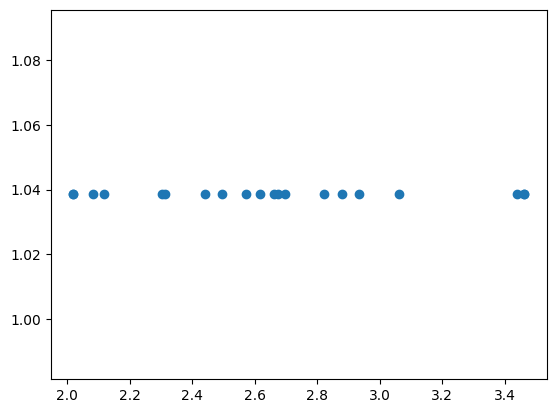

In [ ]:
plt.scatter(t['z_best'],t['Dn4000'])

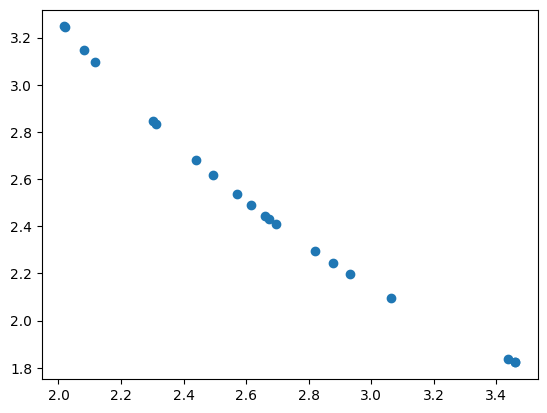

In [ ]:
plt.scatter(t['z_best'],t['age'])